# 02 — Doğrusallaştırma ve sistem analizi

Açıklamalar: **`NOTLAR_Asama1_2.md` → Bölüm 5–10.**

δṡ ≈ A δs + B δF,   A = ∂f/∂s,  B = ∂f/∂F,  (s*, F*) = denge noktası.

| bölüm | soru |
|---|---|
| 1 | A, B nedir, hangi parametreye nasıl bağlı? |
| 2 | Kendi hâline bırakınca ne olur? (özdeğerler) — simülasyondan ölç |
| 3 | Tek kuvvetle her şeyi yönetebilir miyim? (kontrol edilebilirlik) |
| 4 | Aşağı denge |
| 5 | F → x: sağ yarı düzlem sıfırı, ters tepki |
| 6 | Ek A.2 |
| 7 | Sayısal Jacobian, ayrıklaştırma |
| 8 | Gözlemlenebilirlik |
| 9 | Doğrusal model nerede bozuluyor? |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, HTML
sp.init_printing()
plt.rcParams['figure.dpi'] = 90

import cartpole as cp
P = cp.CartPoleParams()
fn = cp.make_f(P)
ZERO = lambda t, s: 0.0
import control

---
## 1. Sembolik f(s, F) → Jacobian → denge noktasında değerlendir
Aşama 1'in sonucu (Ek A.1) düz sembollerle.

In [2]:
x, xd, th, thd, F = sp.symbols('x xdot theta thetadot F')
M, m, l, g = sp.symbols('M m l g', positive=True)
den  = M + m*sp.sin(th)**2
xdd  = (F + m*sp.sin(th)*(l*thd**2 - g*sp.cos(th))) / den
thdd = (-F*sp.cos(th) - m*l*thd**2*sp.sin(th)*sp.cos(th) + (M + m)*g*sp.sin(th)) / (l*den)

s = sp.Matrix([x, xd, th, thd])
f = sp.Matrix([xd, xdd, thd, thdd])
A_full, B_full = f.jacobian(s), f.jacobian([F])
at = lambda th0: {x: 0, xd: 0, th: th0, thd: 0, F: 0}

A_up, B_up = sp.simplify(A_full.subs(at(0))), sp.simplify(B_full.subs(at(0)))
display(A_up, B_up)
vals = {M: P.M, m: P.m, l: P.l, g: P.g}
A_n = np.array(A_up.subs(vals), dtype=float); B_n = np.array(B_up.subs(vals), dtype=float)
print(A_n); print(B_n.T)

⎡0  1      0      0⎤
⎢                  ⎥
⎢        -g⋅m      ⎥
⎢0  0    ─────    0⎥
⎢          M       ⎥
⎢                  ⎥
⎢0  0      0      1⎥
⎢                  ⎥
⎢      g⋅(M + m)   ⎥
⎢0  0  ─────────  0⎥
⎣         M⋅l      ⎦

⎡ 0 ⎤
⎢   ⎥
⎢ 1 ⎥
⎢ ─ ⎥
⎢ M ⎥
⎢   ⎥
⎢ 0 ⎥
⎢   ⎥
⎢-1 ⎥
⎢───⎥
⎣M⋅l⎦

[[ 0.     1.     0.     0.   ]
 [ 0.     0.    -0.981  0.   ]
 [ 0.     0.     0.     1.   ]
 [ 0.     0.    21.582  0.   ]]
[[ 0.  1.  0. -2.]]


**Satır satır okuma** (sayısal):
- ẍ ≈ −0.981 θ + 1·F  → sarkaç sağa yatınca araba **sola** itilir; m/M küçük olduğu için zayıf.
- θ̈ ≈ +21.58 θ − 2·F → yatma **kendini büyütür** (+); sağa itmek sarkacı **sola** döndürür (−).

---
## 2. Özdeğerler
Sembolik: λ² = (M+m)g/(Ml) → 0, 0, ±√(...)

In [4]:
display(A_up.eigenvals())
lam = np.linalg.eigvals(A_n)
lp = lam.real.max()
print('sayısal:', np.round(np.sort(lam.real), 4))
print(f'λ = {lp:.3f} 1/s → τ = 1/λ = {1/lp:.3f} s, ikiye katlanma ln2/λ = {np.log(2)/lp:.3f} s')

sayısal: [-4.6456  0.      0.      4.6456]
λ = 4.646 1/s → τ = 1/λ = 0.215 s, ikiye katlanma ln2/λ = 0.149 s


### 👀 Özdeğeri simülasyondan ölç
θ ≈ c·e^{λt} ise log θ zamanla **doğrusal**, eğimi λ. Doğrusal olmayan modeli θ₀ = 0.01'den bırak.

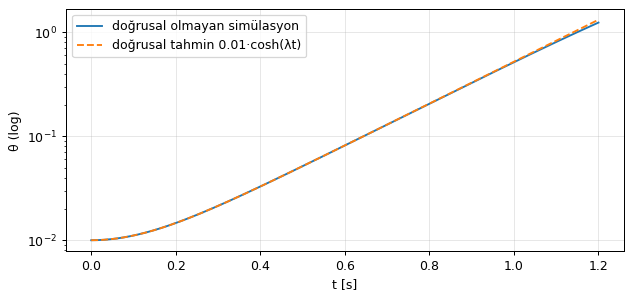

log θ eğimi = 4.568   (λ = 4.646)


In [5]:
tt, SS, _ = cp.simulate(fn, [0, 0, 0.01, 0], ZERO, 0.001, 1.2)
th_ = SS[:, 2]
sel = (tt > 0.3) & (th_ < 0.3)
slope = np.polyfit(tt[sel], np.log(th_[sel]), 1)[0]
plt.figure(figsize=(8, 3.5))
plt.semilogy(tt, th_, label='doğrusal olmayan simülasyon')
plt.semilogy(tt, 0.01*np.cosh(lp*tt), '--', label='doğrusal tahmin 0.01·cosh(λt)')
plt.xlabel('t [s]'); plt.ylabel('θ (log)'); plt.grid(alpha=.3); plt.legend(); plt.show()
print(f'log θ eğimi = {slope:.3f}   (λ = {lp:.3f})')

Eğim λ'dan biraz küçük: (i) seçilen aralığın başında cosh henüz saf e^{λt} değil, (ii) θ → 0.3'e
yaklaşırken sinθ < θ olduğu için gerçek sistem doğrusal tahminden **yavaş** düşüyor.

---
## 3. Kontrol edilebilirlik: 𝒞 = [B, AB, A²B, A³B]
Sütunlar: kuvvetin durumu 1, 2, 3, 4 "türev adımında" hangi yönlere itebildiği.

⎡      1                   g⋅m     ⎤
⎢ 0    ─        0          ────    ⎥
⎢      M                    2      ⎥
⎢                          M ⋅l    ⎥
⎢                                  ⎥
⎢ 1           g⋅m                  ⎥
⎢ ─    0      ────           0     ⎥
⎢ M            2                   ⎥
⎢             M ⋅l                 ⎥
⎢                                  ⎥
⎢     -1                -g⋅(M + m) ⎥
⎢ 0   ───       0       ───────────⎥
⎢     M⋅l                   2  2   ⎥
⎢                          M ⋅l    ⎥
⎢                                  ⎥
⎢-1        -g⋅(M + m)              ⎥
⎢───   0   ───────────       0     ⎥
⎢M⋅l           2  2                ⎥
⎣             M ⋅l                 ⎦

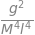

rank 𝒞 = 4 / 4,   koşul sayısı = 4.8e+01


In [6]:
C_sym = sp.Matrix.hstack(B_up, A_up*B_up, A_up**2*B_up, A_up**3*B_up)
display(sp.simplify(C_sym), sp.factor(C_sym.det()))
Cn = control.ctrb(A_n, B_n)
print('rank 𝒞 =', np.linalg.matrix_rank(Cn), '/ 4,   koşul sayısı =', f'{np.linalg.cond(Cn):.1e}')

det 𝒞 = g²/(M⁴l⁴) → g ≠ 0 olduğu sürece hiçbir M, m, l değerinde kontrol edilebilirlik kaybolmuyor. g = 0'da kaybolur: neden? (Notlar 8.2)

---
## 4. Aşağı denge (θ* = π)

In [7]:
A_dn, B_dn = sp.simplify(A_full.subs(at(sp.pi))), sp.simplify(B_full.subs(at(sp.pi)))
display(A_dn, B_dn, A_dn.eigenvals())
w = np.sqrt((P.M + P.m)*P.g/(P.M*P.l))
print(f'ω = {w:.3f} rad/s, periyot = {2*np.pi/w:.3f} s   (sabit pivotlu sarkaç: {2*np.pi/np.sqrt(P.g/P.l):.3f} s)')

⎡0  1       0       0⎤
⎢                    ⎥
⎢         -g⋅m       ⎥
⎢0  0     ─────     0⎥
⎢           M        ⎥
⎢                    ⎥
⎢0  0       0       1⎥
⎢                    ⎥
⎢      -g⋅(M + m)    ⎥
⎢0  0  ───────────  0⎥
⎣          M⋅l       ⎦

⎡ 0 ⎤
⎢   ⎥
⎢ 1 ⎥
⎢ ─ ⎥
⎢ M ⎥
⎢   ⎥
⎢ 0 ⎥
⎢   ⎥
⎢ 1 ⎥
⎢───⎥
⎣M⋅l⎦

ω = 4.646 rad/s, periyot = 1.352 s   (sabit pivotlu sarkaç: 1.419 s)


---
## 5. F → x transfer fonksiyonu, sıfırlar
G(s) = C(sI − A)⁻¹B,  C = [1 0 0 0]

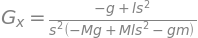

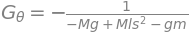

F→x sıfırlar: [-sqrt(g)/sqrt(l), sqrt(g)/sqrt(l)]   kutuplar: [0, -sqrt(g)*sqrt(M + m)/(sqrt(M)*sqrt(l)), sqrt(g)*sqrt(M + m)/(sqrt(M)*sqrt(l))]


In [7]:
sv = sp.symbols('s')
G_x  = sp.factor(sp.simplify((sp.Matrix([[1, 0, 0, 0]])*(sv*sp.eye(4) - A_up).inv()*B_up)[0]))
G_th = sp.factor(sp.simplify((sp.Matrix([[0, 0, 1, 0]])*(sv*sp.eye(4) - A_up).inv()*B_up)[0]))
display(sp.Eq(sp.Symbol('G_x'), G_x), sp.Eq(sp.Symbol('G_θ'), G_th))
num, den_ = sp.fraction(G_x)
print('F→x sıfırlar:', sp.solve(num, sv), '  kutuplar:', sp.solve(den_, sv))

python-control ile. ⚠ `ss2tf` payın başına ~1e-16 artık koyar → sahte ~1e14 sıfır; `cp.transfer_zeros` temizler.

In [8]:
G_raw = control.ss2tf(control.ss(A_n, B_n, [[1, 0, 0, 0]], 0))
print('ham pay      :', G_raw.num[0][0])
print('ham sıfırlar :', control.zeros(G_raw))
z, p_, _, _ = cp.transfer_zeros(A_n, B_n, cp.C_X)
print('temiz sıfırlar:', np.round(z.real, 4), '   √(g/l) =', round(np.sqrt(P.g/P.l), 4))

ham pay      : [ 2.10942375e-15  1.00000000e+00 -5.53777724e-15 -1.96200000e+01]
ham sıfırlar : [-4.74063119e+14+0.j  4.42944692e+00+0.j -4.42944692e+00+0.j]
temiz sıfırlar: [-4.4294  4.4294]    √(g/l) = 4.4294


### 👀 Ters tepki (önizleme)
Sistemi bir durum geri beslemesiyle (Aşama 4'ün konusu; burada sadece kutup yerleştirme) dengede tutup
arabaya "**1 m sağa git**" diyelim. RHP sıfırı yüzünden araba **önce sola** gider: sarkacı sağa yatırmak için.

yavaş kutuplar [-2.0, -2.5, -3.0, -3.5]: en küçük x = -0.030 m,  max|F| = 2.7 N,  max|θ| = 0.09 rad
hızlı kutuplar [-4.0, -5.0, -6.0, -7.0]: en küçük x = -0.161 m,  max|F| = 42.8 N,  max|θ| = 0.38 rad


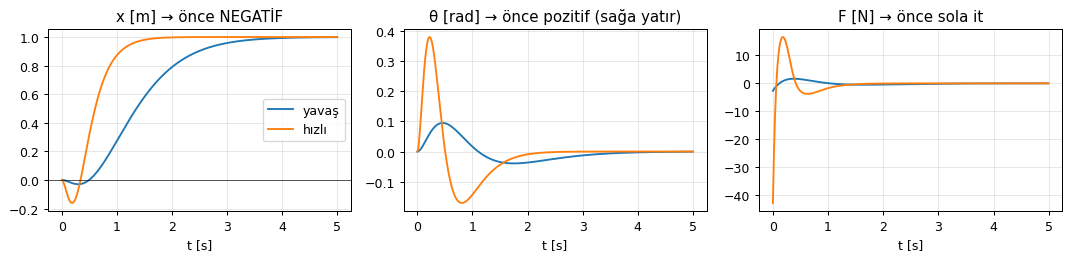

In [9]:
x_ref = np.array([1.0, 0, 0, 0])
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for poles, lbl in (([-2.0, -2.5, -3.0, -3.5], 'yavaş'), ([-4.0, -5.0, -6.0, -7.0], 'hızlı')):
    K = control.place(A_n, B_n, poles)
    tt, SS, UU = cp.simulate(fn, [0, 0, 0, 0], lambda t, s: float((-K @ (s - x_ref))[0]), 0.01, 5.0)
    ax[0].plot(tt, SS[:, 0], label=lbl); ax[1].plot(tt, SS[:, 2]); ax[2].plot(tt[:-1], UU)
    print(f'{lbl:5s} kutuplar {poles}: en küçük x = {SS[:, 0].min():+.3f} m,  max|F| = {np.abs(UU).max():.1f} N,  max|θ| = {np.abs(SS[:, 2]).max():.2f} rad')
ax[0].axhline(0, color='k', lw=.5); ax[0].set(title='x [m] → önce NEGATİF', xlabel='t [s]'); ax[0].legend()
ax[1].set(title='θ [rad] → önce pozitif (sağa yatır)', xlabel='t [s]'); ax[2].set(title='F [N] → önce sola it', xlabel='t [s]')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Kontrolcü hızlandıkça ters sapma büyüyor (−3 cm → −16 cm) ve kuvvet patlıyor. RHP sıfırı, ulaşılabilir hızı
**temelden** sınırlar: hiçbir kontrolcü bu ters tepkiyi yok edemez, sadece yavaşlayarak küçültebilir.

---
## 6. 🔍 Ek A.2 ile karşılaştırma ve `cartpole.analytic_AB`

In [10]:
A_ref = sp.Matrix([[0, 1, 0, 0], [0, 0, -m*g/M, 0], [0, 0, 0, 1], [0, 0, (M + m)*g/(M*l), 0]])
B_ref = sp.Matrix([0, 1/M, 0, -1/(M*l)])
print('A − A_ref =', sp.simplify(A_up - A_ref) == sp.zeros(4, 4), '   B − B_ref =', sp.simplify(B_up - B_ref) == sp.zeros(4, 1))
for th0, Ad, Bd in [(0, A_up, B_up), (np.pi, A_dn, B_dn)]:
    Aa, Ba = cp.analytic_AB(P, th0)
    print(f'θ*={th0:.2f}: |analytic_AB − sympy| =', np.abs(Aa - np.array(Ad.subs(vals), dtype=float)).max(),
          np.abs(Ba - np.array(Bd.subs(vals), dtype=float)).max())

A − A_ref = True    B − B_ref = True
θ*=0.00: |analytic_AB − sympy| = 3.552713678800501e-15 0.0
θ*=3.14: |analytic_AB − sympy| = 3.552713678800501e-15 0.0


---
## 7. Sayısal Jacobian ve ayrıklaştırma

In [11]:
for name, ss in (('yukarı', cp.UP), ('aşağı', cp.DOWN)):
    Aa, Ba = cp.analytic_AB(P, ss[2]); An_, Bn_ = cp.numeric_AB(fn, ss, 0.0)
    print(f'{name:6s} max|A−A_num| = {np.abs(Aa - An_).max():.1e}  max|B−B_num| = {np.abs(Ba - Bn_).max():.1e}')

dt = 0.02
A_d, B_d = cp.discretize(A_n, B_n, dt)
sysd = control.c2d(control.ss(A_n, B_n, np.eye(4), 0), dt, method='zoh')
print('\nc2d ile fark:', np.abs(A_d - sysd.A).max(), np.abs(B_d - sysd.B).max())
print('A_d =\n', np.round(A_d, 5)); print('B_d =', np.round(B_d.ravel(), 6))
print('|z| =', np.round(np.sort(np.abs(np.linalg.eigvals(A_d))), 5), '   e^(λ dt) =', np.round(np.exp(np.sort(lam.real)*dt), 5))

yukarı max|A−A_num| = 5.8e-12  max|B−B_num| = 0.0e+00
aşağı  max|A−A_num| = 3.0e-09  max|B−B_num| = 0.0e+00

c2d ile fark: 0.0 0.0
A_d =
 [[ 1.00000e+00  2.00000e-02 -2.00000e-04 -0.00000e+00]
 [ 0.00000e+00  1.00000e+00 -1.96500e-02 -2.00000e-04]
 [ 0.00000e+00  0.00000e+00  1.00432e+00  2.00300e-02]
 [ 0.00000e+00  0.00000e+00  4.32260e-01  1.00432e+00]]
B_d = [ 0.0002    0.020003 -0.0004   -0.040058]
|z| = [0.91127 1.      1.      1.09737]    e^(λ dt) = [0.91127 1.      1.      1.09737]


Ayrık modelin, sürekli modelin dt aralıklarla örneklenmiş tam çözümüyle aynı olduğunu göster:

In [12]:
from scipy.integrate import solve_ivp
s0 = np.array([0.1, -0.2, 0.05, 0.3]); u = 2.0; n = 50
S_d = cp.simulate_linear(A_d, B_d, s0, u, n)
te = np.arange(n + 1)*dt
sol = solve_ivp(lambda t, s: A_n @ s + B_n[:, 0]*u, (0, te[-1]), s0, t_eval=te, rtol=1e-12, atol=1e-12, method='DOP853')
print('max |ayrık − örneklenmiş sürekli| =', f'{np.abs(S_d - sol.y.T).max():.1e}')

max |ayrık − örneklenmiş sürekli| = 4.8e-11


---
## 8. Gözlemlenebilirlik (Aşama 5 için)

In [13]:
for name, C in (('sadece x', cp.C_X), ('sadece θ', cp.C_THETA), ('x ve θ', np.vstack([cp.C_X, cp.C_THETA]))):
    print(f'{name:9s} rank 𝒪 = {np.linalg.matrix_rank(cp.obsv_matrix(A_n, C))} / 4')

sadece x  rank 𝒪 = 4 / 4
sadece θ  rank 𝒪 = 2 / 4
x ve θ    rank 𝒪 = 4 / 4


Sadece θ ölçülürse x ve ẋ görünmez: A'nın θ satırları x'e bağlı değil → sabit hızla kayan araba θ'da hiç iz bırakmaz.

---
## 9. Doğrusal vs doğrusal olmayan: θ₀ = 0.05, 0.2, 0.5 rad, F = 0, 1 s
"Ayrışma" = θ'da %10 göreli hata (eşik bizim seçimimiz).

   θ₀ | ayrışma t |       o anki θ | θ(1s) nl | θ(1s) lin
 0.05 |    0.911s | 1.56 rad ( 90°) |     2.20 |      2.60
 0.20 |    0.602s | 1.50 rad ( 86°) |     4.67 |     10.41
 0.50 |    0.375s | 1.34 rad ( 77°) |     5.46 |     26.03


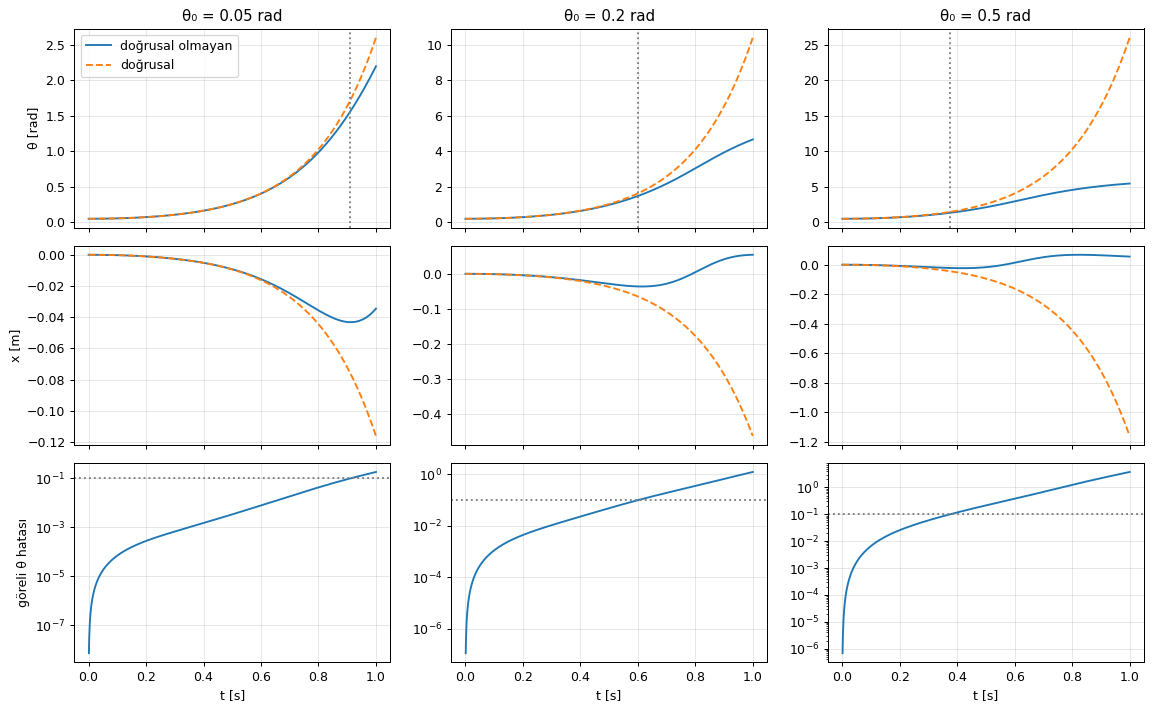

In [14]:
A_d1, B_d1 = cp.discretize(A_n, B_n, 0.001)
fig, ax = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
print(f"{'θ₀':>5} | {'ayrışma t':>9} | {'o anki θ':>14} | {'θ(1s) nl':>8} | {'θ(1s) lin':>9}")
for j, th0 in enumerate((0.05, 0.2, 0.5)):
    s0 = np.array([0, 0, th0, 0.0])
    tt, S_nl, _ = cp.simulate(fn, s0, ZERO, 0.001, 1.0)
    S_l = cp.simulate_linear(A_d1, B_d1, s0, 0.0, len(tt) - 1)
    rel = np.abs(S_l[:, 2] - S_nl[:, 2]) / np.abs(S_nl[:, 2])
    k = np.argmax(rel > 0.10)
    print(f'{th0:5.2f} | {tt[k]:8.3f}s | {S_nl[k,2]:.2f} rad ({np.degrees(S_nl[k,2]):3.0f}°) | {S_nl[-1,2]:8.2f} | {S_l[-1,2]:9.2f}')
    ax[0, j].plot(tt, S_nl[:, 2], label='doğrusal olmayan'); ax[0, j].plot(tt, S_l[:, 2], '--', label='doğrusal')
    ax[0, j].axvline(tt[k], color='gray', ls=':'); ax[0, j].set_title(f'θ₀ = {th0} rad')
    ax[1, j].plot(tt, S_nl[:, 0]); ax[1, j].plot(tt, S_l[:, 0], '--')
    ax[2, j].semilogy(tt[1:], rel[1:]); ax[2, j].axhline(0.1, color='gray', ls=':'); ax[2, j].set_xlabel('t [s]')
ax[0, 0].set_ylabel('θ [rad]'); ax[1, 0].set_ylabel('x [m]'); ax[2, 0].set_ylabel('göreli θ hatası'); ax[0, 0].legend()
for a in ax.flat: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Okuma:** Belirleyici olan başlangıç açısı değil, **o anki açı**: üç durumda da doğrusal model θ ≈ 75–90°
civarında kopuyor (sinθ ≈ θ orada artık çok yanlış). x çok daha erken ayrışıyor: ẍ'deki sinθ·cosθ ve θ̇² terimleri
doğrusal modelde yok. Sonuç: **doğrusal model, sarkacı dik tutan bir kontrolcü için yeterli; sarkaç düştükten
sonrasını anlatmak için değil.**